# Heat Index forecasting: PyTorch baseline

This Colab notebook performs a **retrospective 12:00 UTC (17:30 IST)
ERA5 Heat Index hindcast** for a 5×5 Delhi grid. It uses 30 daily
maps of context to forecast the next three daily maps (t+1, t+2,
t+3). It is not an operational seven-day forecast.

Design safeguards:

- only daily-contiguous windows are used; no window crosses the
  March–July seasonal gaps;
- feature normalization, checkpoint selection, and bias calibration
  cannot read the test targets;
- the model predicts raw °C Heat Index values, then impact categories
  are assigned post-hoc at every grid cell.


In [1]:
# Colab dependencies. This notebook intentionally does not use TensorFlow.
%pip -q install xarray netCDF4 scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 50.5 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import json
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import xarray as xr

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset

# Mount Drive in Colab. Change DATA_PATH if your NetCDF file is elsewhere.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

DATA_PATH = Path(
    '/content/drive/MyDrive/Datasets/Merged_Files/era5_delhi_1981_2025.nc'
)
SAVE_DIR = Path('/content/heat_index_pytorch_outputs')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
INPUT_LENGTH = 30
OUTPUT_LENGTH = 3
N_FEATURES = 18
GRID_SHAPE = (5, 5)
BATCH_SIZE = 16
MAX_EPOCHS = 150
LEARNING_RATE = 3e-4
EARLY_STOPPING_PATIENCE = 25
LR_PATIENCE = 10
MIN_LR = 1e-6
MIN_DELTA = 1e-4
NUM_WORKERS = 2

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEMORY = DEVICE.type == 'cuda'
print(f'Using device: {DEVICE}')
print(f'Artifacts will be saved to: {SAVE_DIR}')

assert DATA_PATH.exists(), (
    f'NetCDF file not found: {DATA_PATH}. Update DATA_PATH before continuing.'
)


Mounted at /content/drive
Using device: cuda
Artifacts will be saved to: /content/heat_index_pytorch_outputs


In [3]:
# Load the once-daily ERA5 slice. valid_time is treated as UTC.
ds = xr.open_dataset(DATA_PATH).sortby('valid_time')
required_raw = {'tp', 'ssrd', 't2m', 'd2m', 'sp', 'u10', 'v10'}
missing_raw = required_raw.difference(ds.data_vars)
assert not missing_raw, f'Missing required ERA5 fields: {missing_raw}'
assert {'valid_time', 'latitude', 'longitude'}.issubset(ds.dims), ds.dims

initial_dates = pd.DatetimeIndex(ds.valid_time.values)
initial_steps = np.diff(initial_dates.to_numpy())
unique_steps, step_counts = np.unique(initial_steps, return_counts=True)
print(ds)
print('Time range:', initial_dates.min(), 'to', initial_dates.max())
print('Time-step counts:', dict(zip(map(str, unique_steps), step_counts)))
print(
    'Target definition: Heat Index derived from the 12:00 UTC ERA5 '
    'temperature and dew-point fields.'
)


<xarray.Dataset> Size: 5MB
Dimensions:     (valid_time: 6885, latitude: 5, longitude: 5)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 55kB 1981-03-01T12:00:00 ... 2025...
  * latitude    (latitude) float64 40B 29.0 28.75 28.5 28.25 28.0
  * longitude   (longitude) float64 40B 76.5 76.75 77.0 77.25 77.5
    number      int64 8B ...
    expver      (valid_time) <U4 110kB ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 688kB ...
    ssrd        (valid_time, latitude, longitude) float32 688kB ...
    t2m         (valid_time, latitude, longitude) float32 688kB ...
    d2m         (valid_time, latitude, longitude) float32 688kB ...
    sp          (valid_time, latitude, longitude) float32 688kB ...
    u10         (valid_time, latitude, longitude) float32 688kB ...
    v10         (valid_time, latitude, longitude) float32 688kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Fore

In [4]:
# Feature engineering. The Heat Index equation is the metric Rothfusz
# polynomial used in the TensorFlow notebook. Below its stated validity
# range, air temperature is retained as the target proxy.
ds['t2m_C'] = ds['t2m'] - 273.15
ds['d2m_C'] = ds['d2m'] - 273.15

def relative_humidity_pct(temperature_c, dewpoint_c):
    return 100.0 * (
        np.exp((17.625 * dewpoint_c) / (243.04 + dewpoint_c))
        / np.exp((17.625 * temperature_c) / (243.04 + temperature_c))
    )

def heat_index_c(temperature_c, rh_pct):
    hi = (
        -8.784695
        + 1.61139411 * temperature_c
        + 2.338549 * rh_pct
        - 0.14611605 * temperature_c * rh_pct
        - 0.012308094 * temperature_c**2
        - 0.016424828 * rh_pct**2
        + 0.002211732 * temperature_c**2 * rh_pct
        + 0.00072546 * temperature_c * rh_pct**2
        - 0.000003582 * temperature_c**2 * rh_pct**2
    )
    return xr.where((temperature_c >= 26.7) & (rh_pct >= 40.0), hi, temperature_c)

ds['RH'] = relative_humidity_pct(ds['t2m_C'], ds['d2m_C'])
ds['HI_C'] = heat_index_c(ds['t2m_C'], ds['RH'])
ds['wind_speed'] = np.sqrt(ds['u10']**2 + ds['v10']**2)
ds['temp_sq'] = ds['t2m_C'] ** 2
ds['rh_sq'] = ds['RH'] ** 2
ds['temp_rh'] = ds['t2m_C'] * ds['RH']
ds['temp_diff'] = ds['t2m_C'] - ds['d2m_C']

# A lag or trend cannot be carried across an annual seasonal gap.
raw_dates = pd.DatetimeIndex(ds.valid_time.values)
is_daily_continuation = np.concatenate(
    ([False], np.diff(raw_dates.to_numpy()) == np.timedelta64(1, 'D'))
)
continuation = xr.DataArray(
    is_daily_continuation,
    dims=('valid_time',),
    coords={'valid_time': ds.valid_time},
)

ds['HI_C_lag1'] = ds['HI_C'].shift(valid_time=1).where(continuation)
ds['t2m_lag1'] = ds['t2m_C'].shift(valid_time=1).where(continuation)
ds['d2m_lag1'] = ds['d2m_C'].shift(valid_time=1).where(continuation)
ds['HI_C_trend'] = (ds['HI_C'] - ds['HI_C'].shift(valid_time=1)).where(continuation)
ds['d2m_trend'] = (ds['d2m_C'] - ds['d2m_C'].shift(valid_time=1)).where(continuation)
ds['t2m_trend'] = (ds['t2m_C'] - ds['t2m_C'].shift(valid_time=1)).where(continuation)

FEATURES = [
    't2m_C', 'd2m_C', 'RH', 'ssrd', 'wind_speed', 'temp_sq', 'rh_sq',
    'temp_rh', 'tp', 'sp', 'HI_C', 'HI_C_lag1', 't2m_lag1',
    'd2m_lag1', 'temp_diff', 'HI_C_trend', 'd2m_trend', 't2m_trend',
]
assert len(FEATURES) == N_FEATURES

# This removes the first day in every contiguous season because its
# lag/trend fields are undefined. No shifted 'tomorrow' target is made.
ds = ds.dropna(dim='valid_time', how='any')
dates = pd.DatetimeIndex(ds.valid_time.values)
X_ALL = (
    ds[FEATURES]
    .to_array()
    .transpose('valid_time', 'variable', 'latitude', 'longitude')
    .values.astype(np.float32)
)
HI_ALL = ds['HI_C'].values.astype(np.float32)

assert X_ALL.shape[1:] == (N_FEATURES, *GRID_SHAPE), X_ALL.shape
assert HI_ALL.shape[1:] == GRID_SHAPE, HI_ALL.shape
print('Feature tensor:', X_ALL.shape)
print('Raw HI target range:', float(HI_ALL.min()), 'to', float(HI_ALL.max()))


Feature tensor: (6840, 18, 5, 5)
Raw HI target range: 14.608795166015625 to 55.706092834472656


In [5]:
# Build t+1:t+3 targets from a 30-day context. A valid candidate spans
# 33 dates, all separated by exactly one day.
WINDOW_SPAN = INPUT_LENGTH + OUTPUT_LENGTH

def window_is_daily_contiguous(start):
    window_dates = dates[start : start + WINDOW_SPAN]
    return (
        len(window_dates) == WINDOW_SPAN
        and np.all(np.diff(window_dates.to_numpy()) == np.timedelta64(1, 'D'))
    )

all_candidate_starts = np.arange(0, len(dates) - WINDOW_SPAN + 1)
valid_starts = np.array(
    [start for start in all_candidate_starts if window_is_daily_contiguous(start)],
    dtype=np.int64,
)
assert len(valid_starts) > 0

target_start_dates = dates[valid_starts + INPUT_LENGTH]
target_end_dates = dates[valid_starts + WINDOW_SPAN - 1]

# Keep the requested chronological 70/15/15 split while avoiding any
# three-day target that straddles a partition boundary.
split_1_index = math.floor(0.70 * len(valid_starts))
split_2_index = math.floor(0.85 * len(valid_starts))
validation_target_start = target_start_dates[split_1_index]
test_target_start = target_start_dates[split_2_index]

train_starts = valid_starts[target_end_dates < validation_target_start]
val_starts = valid_starts[
    (target_start_dates >= validation_target_start)
    & (target_end_dates < test_target_start)
]
test_starts = valid_starts[target_start_dates >= test_target_start]

assert len(train_starts) and len(val_starts) and len(test_starts)
assert all(window_is_daily_contiguous(start) for start in valid_starts)
assert np.all(dates[train_starts + WINDOW_SPAN - 1] < validation_target_start)
assert np.all(dates[val_starts + INPUT_LENGTH] >= validation_target_start)
assert np.all(dates[val_starts + WINDOW_SPAN - 1] < test_target_start)
assert np.all(dates[test_starts + INPUT_LENGTH] >= test_target_start)

def target_values(starts):
    return np.stack(
        [HI_ALL[start + INPUT_LENGTH : start + WINDOW_SPAN] for start in starts]
    ).astype(np.float32)

# The scaler sees only raw feature maps used by training contexts.
train_input_indices = np.unique(
    np.concatenate([np.arange(start, start + INPUT_LENGTH) for start in train_starts])
)
feature_mean = X_ALL[train_input_indices].mean(axis=(0, 2, 3), dtype=np.float64)
feature_std = X_ALL[train_input_indices].std(axis=(0, 2, 3), dtype=np.float64)
feature_std = np.maximum(feature_std, 1e-6)
np.savez(
    SAVE_DIR / 'feature_scaler_train_only.npz',
    feature_names=np.array(FEATURES),
    mean=feature_mean,
    std=feature_std,
)

class HeatIndexSequenceDataset(Dataset):
    def __init__(self, starts, x_all, hi_all, mean, std):
        self.starts = np.asarray(starts, dtype=np.int64)
        self.x_all = x_all
        self.hi_all = hi_all
        self.mean = mean.astype(np.float32).reshape(1, N_FEATURES, 1, 1)
        self.std = std.astype(np.float32).reshape(1, N_FEATURES, 1, 1)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, index):
        start = self.starts[index]
        x = (self.x_all[start : start + INPUT_LENGTH] - self.mean) / self.std
        y = self.hi_all[start + INPUT_LENGTH : start + WINDOW_SPAN]
        return torch.from_numpy(x.copy()), torch.from_numpy(y.copy())

train_dataset = HeatIndexSequenceDataset(
    train_starts, X_ALL, HI_ALL, feature_mean, feature_std
)
val_dataset = HeatIndexSequenceDataset(
    val_starts, X_ALL, HI_ALL, feature_mean, feature_std
)
test_dataset = HeatIndexSequenceDataset(
    test_starts, X_ALL, HI_ALL, feature_mean, feature_std
)

loader_kwargs = {
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'pin_memory': PIN_MEMORY,
    'persistent_workers': NUM_WORKERS > 0,
}
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, shuffle=True, generator=train_generator, **loader_kwargs
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

sample_x, sample_y = next(iter(train_loader))
assert sample_x.shape[1:] == (INPUT_LENGTH, N_FEATURES, *GRID_SHAPE), sample_x.shape
assert sample_y.shape[1:] == (OUTPUT_LENGTH, *GRID_SHAPE), sample_y.shape

split_summary = pd.DataFrame(
    {
        'split': ['train', 'validation', 'test'],
        'windows': [len(train_starts), len(val_starts), len(test_starts)],
        'first_target_date': [
            dates[train_starts[0] + INPUT_LENGTH],
            dates[val_starts[0] + INPUT_LENGTH],
            dates[test_starts[0] + INPUT_LENGTH],
        ],
        'last_target_date': [
            dates[train_starts[-1] + WINDOW_SPAN - 1],
            dates[val_starts[-1] + WINDOW_SPAN - 1],
            dates[test_starts[-1] + WINDOW_SPAN - 1],
        ],
    }
)
display(split_summary)
print('Accepted contiguous windows:', len(valid_starts))
print('Batch shapes:', tuple(sample_x.shape), tuple(sample_y.shape))


,split,windows,first_target_date,last_target_date
0,train,3777,1981-04-01 12:00:00,2012-05-29 12:00:00
1,validation,809,2012-05-30 12:00:00,2019-04-30 12:00:00
2,test,810,2019-05-01 12:00:00,2025-07-31 12:00:00


Accepted contiguous windows: 5400
Batch shapes: (16, 30, 18, 5, 5) (16, 3, 5, 5)


In [6]:
class ConvBiGRU(nn.Module):
    def __init__(self, pool='gap'):   # 'gap' | 'flatten' | 'compress'
        super().__init__()
        self.pool_mode = pool
        self.c1 = nn.Conv2d(N_FEATURES, 32, 3, padding=1)
        self.c2 = nn.Conv2d(32, 32, 3, padding=1)
        if pool == 'gap':
            self.gap = nn.AdaptiveAvgPool2d((1, 1)); gru_in = 32
        elif pool == 'flatten':
            gru_in = 32 * 25
        elif pool == 'compress':
            self.comp = nn.Conv2d(32, 8, 1); gru_in = 8 * 25
        self.gru = nn.GRU(gru_in, 64, batch_first=True, bidirectional=True)
        self.norm = nn.LayerNorm(128)
        self.fc1 = nn.Linear(128, 128)
        self.dropout = nn.Dropout(0.2)
        self.fc_out = nn.Linear(128, OUTPUT_LENGTH * 25)

    def forward(self, x):
        b, t, ch, h, w = x.shape
        z = x.reshape(b * t, ch, h, w)
        z = F.relu(self.c1(z)); z = F.relu(self.c2(z))
        if self.pool_mode == 'gap':
            z = self.gap(z).flatten(1).reshape(b, t, 32)
        elif self.pool_mode == 'flatten':
            z = z.reshape(b, t, 32 * 25)
        elif self.pool_mode == 'compress':
            z = F.relu(self.comp(z)); z = z.reshape(b, t, 8 * 25)
        _, hidden = self.gru(z)
        z = torch.cat((hidden[-2], hidden[-1]), dim=1)
        z = self.norm(z); z = F.relu(self.fc1(z)); z = self.dropout(z)
        z = self.fc_out(z)
        return z.reshape(b, OUTPUT_LENGTH, 5, 5)


# ============ E3: ConvLSTM ablation (spatial-recurrent, defends thesis) ============
class ConvLSTMCell(nn.Module):
    """Single ConvLSTM cell — hidden state is a spatial map, not a vector."""
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        pad = k // 2
        self.hid_ch = hid_ch
        # gates: input, forget, output, cell — computed together
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k, padding=pad)

    def forward(self, x, h, c):
        combined = torch.cat([x, h], dim=1)          # concat on channel axis
        gates = self.conv(combined)
        i, f, o, g = torch.chunk(gates, 4, dim=1)
        i = torch.sigmoid(i); f = torch.sigmoid(f)
        o = torch.sigmoid(o); g = torch.tanh(g)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c


class ConvLSTMNet(nn.Module):
    """
    Conv2D encoder per timestep -> ConvLSTM over 30 steps (keeps 5x5 spatial state)
    -> final spatial hidden state -> conv head -> three 5x5 maps.
    Spatial info is NEVER globally pooled away.
    """
    def __init__(self, hid_ch=24):
        super().__init__()
        self.c1 = nn.Conv2d(N_FEATURES, 32, 3, padding=1)
        self.c2 = nn.Conv2d(32, 32, 3, padding=1)
        self.cell = ConvLSTMCell(32, hid_ch, k=3)
        self.hid_ch = hid_ch
        # decode final spatial hidden map (hid_ch x 5 x 5) -> 3 x 5 x 5
        self.head = nn.Sequential(
            nn.Conv2d(hid_ch, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, OUTPUT_LENGTH, 3, padding=1)
        )

    def forward(self, x):
        b, t, ch, hgt, wid = x.shape
        h = torch.zeros(b, self.hid_ch, hgt, wid, device=x.device)
        c = torch.zeros(b, self.hid_ch, hgt, wid, device=x.device)
        for step in range(t):
            z = x[:, step]                     # [b, 18, 5, 5]
            z = F.relu(self.c1(z)); z = F.relu(self.c2(z))
            h, c = self.cell(z, h, c)          # spatial state updated
        out = self.head(h)                     # [b, 3, 5, 5]
        return out

def mixed_loss(prediction, target):
    weights = torch.where(
        target >= 40.0,
        torch.tensor(4.0, device=target.device),
        torch.where(
            target >= 35.0,
            torch.tensor(2.0, device=target.device),
            torch.tensor(1.0, device=target.device),
        ),
    )
    weighted_mse = torch.mean(weights * (prediction - target).square())
    mae = torch.mean(torch.abs(prediction - target))
    return 0.7 * weighted_mse + 0.3 * mae

model = ConvBiGRU(pool='gap').to(DEVICE)       # run 1: current baseline (already have this)
# model = ConvBiGRU(pool='flatten').to(DEVICE)   # run 2: full spatial retention
# model = ConvBiGRU(pool='compress').to(DEVICE)   # run 2: full spatial retention

# model = ConvLSTMNet(hid_ch=24).to(DEVICE)  # run 3: middle ground (200-dim, not 800)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(model)
print(f'Trainable parameters: {parameter_count:,}')
assert model(sample_x[:2].to(DEVICE)).shape == (2, OUTPUT_LENGTH, *GRID_SHAPE)


ConvBiGRU(
  (c1): Conv2d(18, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (c2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (gru): GRU(32, 64, batch_first=True, bidirectional=True)
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc_out): Linear(in_features=128, out_features=75, bias=True)
)
Trainable parameters: 78,539


Epoch 001 | train MAE 18.3400 | val MAE 2.5039 | LR 3.00e-04
Epoch 002 | train MAE 3.3092 | val MAE 2.2872 | LR 3.00e-04
Epoch 003 | train MAE 3.1326 | val MAE 2.2261 | LR 3.00e-04
Epoch 004 | train MAE 3.1619 | val MAE 2.2788 | LR 3.00e-04
Epoch 005 | train MAE 3.0669 | val MAE 2.2855 | LR 3.00e-04
Epoch 006 | train MAE 3.0910 | val MAE 2.2020 | LR 3.00e-04
Epoch 007 | train MAE 3.0246 | val MAE 2.2776 | LR 3.00e-04
Epoch 008 | train MAE 2.9994 | val MAE 2.2381 | LR 3.00e-04
Epoch 009 | train MAE 2.9757 | val MAE 2.2461 | LR 3.00e-04
Epoch 010 | train MAE 2.8896 | val MAE 2.1930 | LR 3.00e-04
Epoch 011 | train MAE 2.9021 | val MAE 2.2065 | LR 3.00e-04
Epoch 012 | train MAE 2.8869 | val MAE 2.2055 | LR 3.00e-04
Epoch 013 | train MAE 2.8618 | val MAE 2.2180 | LR 3.00e-04
Epoch 014 | train MAE 2.8798 | val MAE 2.2132 | LR 3.00e-04
Epoch 015 | train MAE 2.8270 | val MAE 2.2108 | LR 3.00e-04
Epoch 016 | train MAE 2.8767 | val MAE 2.3025 | LR 3.00e-04
Epoch 017 | train MAE 2.8012 | val MAE 

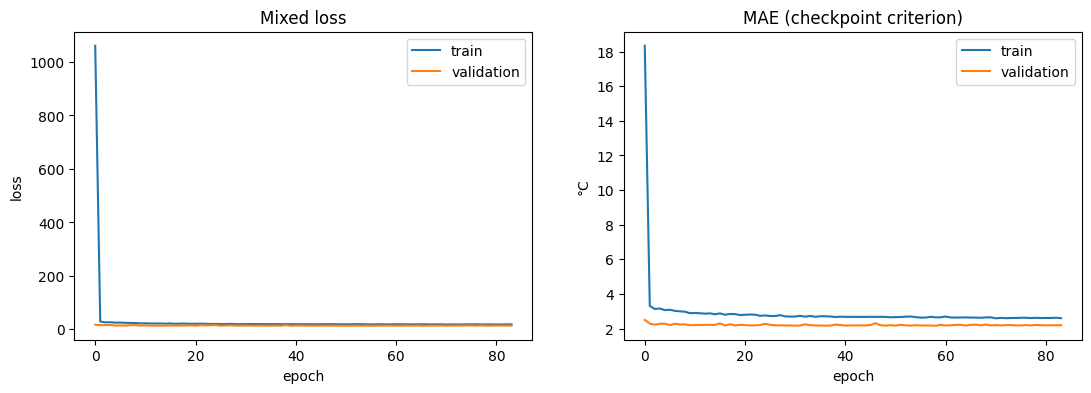

In [7]:
# Train with the original mixed loss, but select checkpoints and adjust
# learning rate by validation MAE because MAE is the stated objective.

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
)

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_absolute_error = 0.0
    total_values = 0

    for x_batch, y_batch in loader:
        x_batch = x_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            prediction = model(x_batch)
            loss = mixed_loss(prediction, y_batch)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.detach().item() * x_batch.size(0)
        total_absolute_error += (
            torch.abs(prediction.detach() - y_batch).sum().item()
        )
        total_values += y_batch.numel()

    return {
        'loss': total_loss / len(loader.dataset),
        'mae': total_absolute_error / total_values,
    }

checkpoint_path = SAVE_DIR / 'best_conv_bigru_by_val_mae.pt'
training_config = {
    'seed': SEED,
    'input_length': INPUT_LENGTH,
    'output_length': OUTPUT_LENGTH,
    'features': FEATURES,
    'architecture': 'Conv2D(32)-Conv2D(32)-GAP-BiGRU(64)-Dense(128)',
    'loss': '0.7 * weighted_mse(>=35:2, >=40:4) + 0.3 * mae',
    'selection_metric': 'validation MAE',
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
}
with open(SAVE_DIR / 'training_config_seed.json', 'w', encoding='utf-8') as file:
    json.dump(training_config, file, indent=2)

history = []
best_val_mae = float('inf')
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)
    scheduler.step(val_metrics['mae'])
    current_lr = optimizer.param_groups[0]['lr']
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_mae': train_metrics['mae'],
        'val_loss': val_metrics['loss'],
        'val_mae': val_metrics['mae'],
        'learning_rate': current_lr,
    }
    history.append(row)
    print(
        f"Epoch {epoch:03d} | train MAE {row['train_mae']:.4f} | "
        f"val MAE {row['val_mae']:.4f} | LR {current_lr:.2e}"
    )

    if val_metrics['mae'] < best_val_mae - MIN_DELTA:
        best_val_mae = val_metrics['mae']
        epochs_without_improvement = 0
        torch.save(
            {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'validation_mae': best_val_mae,
                'config': training_config,
            },
            checkpoint_path,
        )
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f'Early stopping at epoch {epoch}; best val MAE={best_val_mae:.4f}')
            break

history_df = pd.DataFrame(history)
history_df.to_csv(SAVE_DIR / 'training_history_e3_132.csv', index=False)
checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
print(
    f"Restored epoch {checkpoint['epoch']} with validation MAE "
    f"{checkpoint['validation_mae']:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df['train_loss'], label='train')
axes[0].plot(history_df['val_loss'], label='validation')
axes[0].set(title='Mixed loss', xlabel='epoch', ylabel='loss')
axes[0].legend()
axes[1].plot(history_df['train_mae'], label='train')
axes[1].plot(history_df['val_mae'], label='validation')
axes[1].set(title='MAE (checkpoint criterion)', xlabel='epoch', ylabel='°C')
axes[1].legend()
plt.show()


In [8]:
# Cell to check for distribution shift and confirm the initial shift of reasoning which was pointed earlier that validation years have gotten hotter

for name, starts in [('train', train_starts), ('val', val_starts), ('test', test_starts)]:
    target_indices = np.concatenate(
        [np.arange(s + INPUT_LENGTH, s + WINDOW_SPAN) for s in starts]
    )
    years = dates[target_indices].year
    print(name, 'mean HI:', HI_ALL[target_indices].mean(),
          'years:', years.min(), '-', years.max())

train mean HI: 38.250755 years: 1981 - 2012
val mean HI: 38.979195 years: 2012 - 2019
test mean HI: 39.30923 years: 2019 - 2025


In [9]:
@torch.no_grad()
def collect_predictions(loader):
    model.eval()
    predictions, targets = [], []
    for x_batch, y_batch in loader:
        predictions.append(model(x_batch.to(DEVICE, non_blocking=True)).cpu().numpy())
        targets.append(y_batch.numpy())
    return np.concatenate(predictions), np.concatenate(targets)

pred_val_raw, y_val = collect_predictions(val_loader)
pred_test_raw, y_test = collect_predictions(test_loader)

# Predeclared post-hoc calibration: one additive bias per forecast lead,
# estimated only from validation residuals then frozen for the test set.
lead_bias = (y_val - pred_val_raw).mean(axis=(0, 2, 3)).reshape(1, OUTPUT_LENGTH, 1, 1)
pred_val = pred_val_raw + lead_bias
pred_test = pred_test_raw + lead_bias
np.save(SAVE_DIR / 'validation_lead_bias_celsius.npy', lead_bias)
print('Validation-only lead bias (°C):', lead_bias.ravel())

def regression_metrics(y_true, y_pred):
    result = {
        'overall_mae': float(np.mean(np.abs(y_pred - y_true))),
        'per_lead_mae': [],
        'per_lead_severe_tail_mae': [],
    }
    for lead in range(OUTPUT_LENGTH):
        true_lead = y_true[:, lead]
        pred_lead = y_pred[:, lead]
        result['per_lead_mae'].append(float(np.mean(np.abs(pred_lead - true_lead))))
        severe_mask = true_lead >= 40.0
        result['per_lead_severe_tail_mae'].append(
            float(np.mean(np.abs(pred_lead[severe_mask] - true_lead[severe_mask])))
            if severe_mask.any()
            else float('nan')
        )
    severe_mask = y_true >= 40.0
    result['severe_tail_mae'] = (
        float(np.mean(np.abs(y_pred[severe_mask] - y_true[severe_mask])))
        if severe_mask.any()
        else float('nan')
    )
    return result

# Correct raw persistence: repeat the last observed raw HI map from the
# 30-day context. This never uses standardized values.
last_hi_test = np.stack(
    [HI_ALL[start + INPUT_LENGTH - 1] for start in test_starts]
)
persistence_pred = np.repeat(last_hi_test[:, None], OUTPUT_LENGTH, axis=1)

# Train-only day-of-season climatology, calculated from unique target
# dates rather than test data.
train_target_indices = np.unique(
    np.concatenate(
        [np.arange(start + INPUT_LENGTH, start + WINDOW_SPAN) for start in train_starts]
    )
)
climatology_sum, climatology_count = {}, {}
for time_index in train_target_indices:
    key = (dates[time_index].month, dates[time_index].day)
    climatology_sum[key] = climatology_sum.get(key, 0.0) + HI_ALL[time_index]
    climatology_count[key] = climatology_count.get(key, 0) + 1

def climatology_map(date):
    key = (date.month, date.day)
    assert key in climatology_sum, f'No training climatology for {key}'
    return climatology_sum[key] / climatology_count[key]

climatology_pred = np.stack(
    [
        np.stack(
            [climatology_map(dates[start + INPUT_LENGTH + lead]) for lead in range(OUTPUT_LENGTH)]
        )
        for start in test_starts
    ]
).astype(np.float32)

regression_results = {
    'test_raw_model': regression_metrics(y_test, pred_test_raw),
    'test_validation_bias_calibrated_model': regression_metrics(y_test, pred_test),
    'test_raw_persistence': regression_metrics(y_test, persistence_pred),
    'test_train_only_day_of_season_climatology': regression_metrics(
        y_test, climatology_pred
    ),
}
display(pd.DataFrame(regression_results).T)


Validation-only lead bias (°C): [-0.2645693  -0.16701436 -0.17350328]


,overall_mae,per_lead_mae,per_lead_severe_tail_mae,severe_tail_mae
test_raw_model,2.555455,"[2.319775342941284, 2.590153694152832, 2.75643...","[2.4130632877349854, 2.7723608016967773, 2.926...",2.705784
test_validation_bias_calibrated_model,2.568098,"[2.330151319503784, 2.602642059326172, 2.77150...","[2.585472345352173, 2.8923707008361816, 3.0587...",2.847165
test_raw_persistence,2.896615,"[2.2824463844299316, 3.0033376216888428, 3.404...","[2.2252297401428223, 2.908017158508301, 3.2800...",2.808054
test_train_only_day_of_season_climatology,3.09579,"[3.0846710205078125, 3.0944039821624756, 3.108...","[3.876026153564453, 3.889775037765503, 3.89246...",3.886145


Custom bands: green <35°C, yellow 35–<40°C, severe ≥40°C
Custom test metrics: {'macro_f1': 0.6188766170043908, 'severe_precision': 0.7112075198843095, 'severe_recall': 0.7458012662546916}
IMD four-colour test metrics: {'macro_f1': 0.34396566103239584, 'severe_precision': 0.0, 'severe_recall': 0.0}


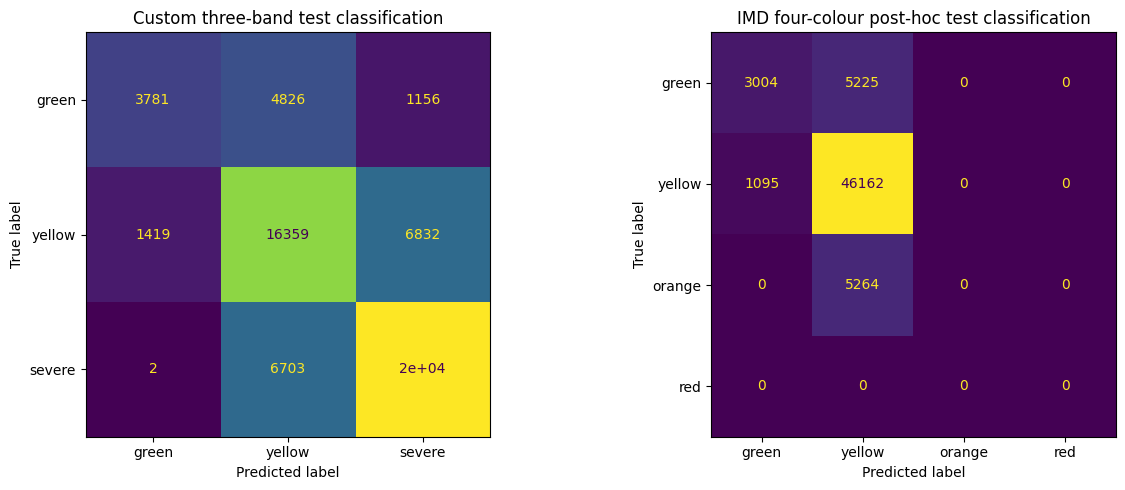

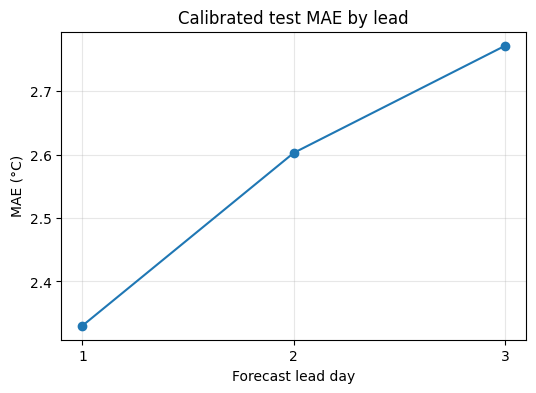

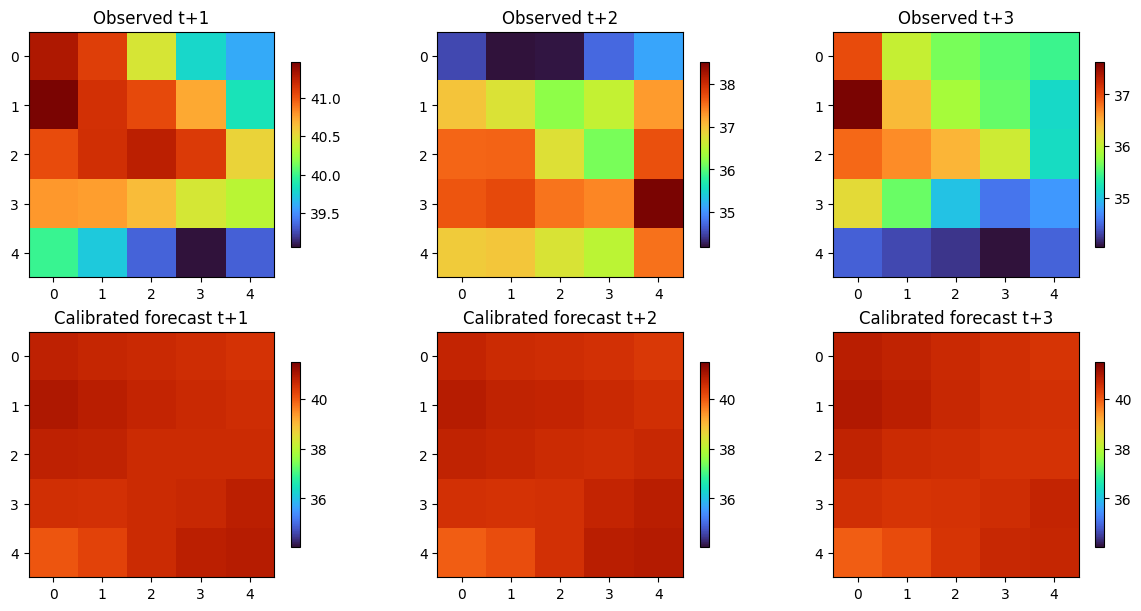

In [10]:
# Stage 2: post-hoc impact classification at every grid cell. The three
# custom bands are the modelling task; IMD colours are reported
# separately after rounding predicted/observed HI to whole °C.
def custom_three_band(hi_c):
    return np.where(hi_c < 35.0, 0, np.where(hi_c < 40.0, 1, 2)).astype(np.int8)

def imd_four_colour(hi_c):
    rounded = np.rint(hi_c)
    return np.where(
        rounded <= 34,
        0,
        np.where(rounded <= 45, 1, np.where(rounded <= 55, 2, 3)),
    ).astype(np.int8)

def classification_metrics(y_true, y_pred, classifier, labels, severe_label):
    true_class = classifier(y_true).reshape(-1)
    pred_class = classifier(y_pred).reshape(-1)
    return {
        'macro_f1': float(
            f1_score(true_class, pred_class, labels=labels, average='macro', zero_division=0)
        ),
        'severe_precision': float(
            precision_score(
                true_class, pred_class, labels=[severe_label],
                average='macro', zero_division=0
            )
        ),
        'severe_recall': float(
            recall_score(
                true_class, pred_class, labels=[severe_label],
                average='macro', zero_division=0
            )
        ),
        'confusion_matrix': confusion_matrix(true_class, pred_class, labels=labels).tolist(),
        'per_lead': [
            {
                'macro_f1': float(
                    f1_score(
                        classifier(y_true[:, lead]).reshape(-1),
                        classifier(y_pred[:, lead]).reshape(-1),
                        labels=labels, average='macro', zero_division=0,
                    )
                ),
                'severe_recall': float(
                    recall_score(
                        classifier(y_true[:, lead]).reshape(-1),
                        classifier(y_pred[:, lead]).reshape(-1),
                        labels=[severe_label], average='macro', zero_division=0,
                    )
                ),
            }
            for lead in range(OUTPUT_LENGTH)
        ],
    }

custom_results = classification_metrics(
    y_test, pred_test, custom_three_band, labels=[0, 1, 2], severe_label=2
)
imd_results = classification_metrics(
    y_test, pred_test, imd_four_colour, labels=[0, 1, 2, 3], severe_label=3
)
impact_results = {
    'custom_three_band': custom_results,
    'imd_four_colour_post_hoc': imd_results,
}
with open(SAVE_DIR / 'test_metrics.json', 'w', encoding='utf-8') as file:
    json.dump(
        {
            'regression': regression_results,
            'impact_classification': impact_results,
            'lead_bias_celsius': lead_bias.ravel().tolist(),
        },
        file,
        indent=2,
    )

print('Custom bands: green <35°C, yellow 35–<40°C, severe ≥40°C')
print('Custom test metrics:', {
    key: custom_results[key]
    for key in ['macro_f1', 'severe_precision', 'severe_recall']
})
print('IMD four-colour test metrics:', {
    key: imd_results[key]
    for key in ['macro_f1', 'severe_precision', 'severe_recall']
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(
    np.array(custom_results['confusion_matrix']),
    display_labels=['green', 'yellow', 'severe'],
).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Custom three-band test classification')
ConfusionMatrixDisplay(
    np.array(imd_results['confusion_matrix']),
    display_labels=['green', 'yellow', 'orange', 'red'],
).plot(ax=axes[1], colorbar=False)
axes[1].set_title('IMD four-colour post-hoc test classification')
plt.tight_layout()
plt.show()

lead_mae = regression_results['test_validation_bias_calibrated_model']['per_lead_mae']
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, OUTPUT_LENGTH + 1), lead_mae, marker='o')
plt.xticks(np.arange(1, OUTPUT_LENGTH + 1))
plt.xlabel('Forecast lead day')
plt.ylabel('MAE (°C)')
plt.title('Calibrated test MAE by lead')
plt.grid(alpha=0.3)
plt.show()

# Visual diagnostic for the first test window: raw target and calibrated
# prediction maps for t+1, t+2, and t+3.
example = 0
fig, axes = plt.subplots(2, OUTPUT_LENGTH, figsize=(12, 6), constrained_layout=True)
for lead in range(OUTPUT_LENGTH):
    observed = axes[0, lead].imshow(y_test[example, lead], cmap='turbo')
    axes[0, lead].set_title(f'Observed t+{lead + 1}')
    plt.colorbar(observed, ax=axes[0, lead], shrink=0.75)
    forecast = axes[1, lead].imshow(
        pred_test[example, lead], cmap='turbo',
        vmin=y_test[example].min(), vmax=y_test[example].max(),
    )
    axes[1, lead].set_title(f'Calibrated forecast t+{lead + 1}')
    plt.colorbar(forecast, ax=axes[1, lead], shrink=0.75)
plt.show()


In [11]:
def permutation_importance(model, loader, device, n_repeats=8, seed=42):
    rng = np.random.default_rng(seed)
    model.eval()
    x_all, y_all = [], []
    for xb, yb in loader:
        x_all.append(xb.numpy()); y_all.append(yb.numpy())
    x_all = np.concatenate(x_all); y_all = np.concatenate(y_all)

    def mae_of(x_arr):
        with torch.no_grad():
            preds = model(torch.from_numpy(x_arr).to(device)).cpu().numpy()
        return np.mean(np.abs(preds - y_all))

    baseline = mae_of(x_all)
    results = {}
    for feat_idx, feat_name in enumerate(FEATURES):
        deltas = []
        for _ in range(n_repeats):
            x_perm = x_all.copy()
            perm = rng.permutation(len(x_perm))
            x_perm[:, :, feat_idx, :, :] = x_perm[perm][:, :, feat_idx, :, :]
            deltas.append(mae_of(x_perm) - baseline)
        results[feat_name] = (np.mean(deltas), np.std(deltas))
    return results

## Controlled follow-up MAE experiments

Keep the exact continuity rule, splits, feature-scaler fit, seed set,
validation-only calibration, and test table fixed. Change one factor at
a time:

1. loss: mixed loss vs. MAE vs. SmoothL1;
2. feature set: all 18 features vs. removal of redundant lag/trend
   features already represented by the 30-day context;
3. compact feature model: retain only the meteorological and current
   HI fields, with all architectural settings unchanged.

Do not tune on test results. The four-colour IMD result is a post-hoc
impact mapping, not a declaration of IMD heatwave conditions.
